# 08 — Análise longitudinal espacial do ENEM

## Objetivo

Investigar a evolução espacial do desempenho municipal no ENEM, por meio de mapas de referência, mapas de variação entre os extremos de cada período e mapas de tendência municipal.

A análise respeita as duas estruturas históricas de avaliação:

| Período | Indicadores | Redação |
|---|---|---|
| **1998–2008** | OBJETIVA | critério antigo |
| **2009–2025** | CN, CH, LC e MT | critério novo |

**Regra metodológica:** não será construída uma série longitudinal contínua entre os períodos. A Redação antiga e a nova são analisadas separadamente; OBJETIVA não é comparada às quatro áreas.

## Estratégia cartográfica

Não será produzido um mapa para cada ano. Serão usados três anos de referência por período, desde que existam dados:

- 1998–2008: 1998, 2003 e 2008.
- 2009–2025: 2009, 2017 e 2025.

Os mapas de referência permitem observar a distribuição espacial em momentos selecionados. Os mapas de variação mostram a diferença entre o primeiro e o último ano de cada período. Os mapas de tendência representam a inclinação temporal municipal estimada com todos os anos disponíveis.

As análises estatísticas, rankings e distribuições permanecem nos notebooks longitudinais já existentes. Este notebook concentra-se na representação espacial.


## 1. Configuração e carga dos dados

Ajuste a UF no início. A função `read_allfiles()` já realiza a leitura das bases e a harmonização dos nomes municipais com a malha geográfica. Não repetimos essa normalização neste notebook.


In [1]:
# ============================================================
# 1. CONFIGURAÇÃO, IMPORTAÇÕES E LEITURA
# ============================================================

from _setup import *

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

from matplotlib.colors import Normalize, TwoSlopeNorm
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Patch

from enem_pipeline.config import PROJECT_ROOT, UF_PROCESSAMENTO
from utils.features_names import read_allfiles
from utils.eda import (
    PERIODOS,
    DISCIPLINAS_ANTIGO,
    DISCIPLINAS_NOVO,
    calcular_tendencias_municipais,
)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

# ------------------------------------------------------------
# Parâmetros definidos para esta execução
# ------------------------------------------------------------

UF_PROCESSAMENTO = "PA"

ANOS_REFERENCIA = {
    "1998_2008": [1998, 2003, 2008],
    "2009_2025": [2009, 2017, 2025],
}

MIN_ANOS_TENDENCIA = 5
ALPHA_TENDENCIA = 0.05

# ------------------------------------------------------------
# Leitura única da camada de Consumo
# ------------------------------------------------------------

out = read_allfiles(UF_PROCESSAMENTO)

painel = out["painel"]["data"].copy()
municipios_geo = out["shape"]["data"].copy()

# ------------------------------------------------------------
# Estruturas históricas e validações iniciais
# ------------------------------------------------------------

DISCIPLINAS_PERIODOS = {
    "1998_2008": DISCIPLINAS_ANTIGO,
    "2009_2025": DISCIPLINAS_NOVO,
}

COLUNA_CODIGO_PAINEL = "CO_MUNICIPIO_TERRITORIO"
COLUNA_CODIGO_SHAPE = "CD_MUN"

colunas_obrigatorias = [
    "ano",
    COLUNA_CODIGO_PAINEL,
    "NO_MUNICIPIO_TERRITORIO",
]

faltantes = [c for c in colunas_obrigatorias if c not in painel.columns]
if faltantes:
    raise KeyError(f"Colunas ausentes no painel municipal: {faltantes}")

if COLUNA_CODIGO_SHAPE not in municipios_geo.columns:
    raise KeyError(
        f"Coluna {COLUNA_CODIGO_SHAPE!r} ausente na malha geográfica."
    )

# Conversão numérica do ano.
painel["ano"] = pd.to_numeric(painel["ano"], errors="coerce")
painel = painel[painel["ano"].notna()].copy()
painel["ano"] = painel["ano"].astype(int)

# Chave auxiliar para junções: não altera os nomes municipais.
def codigo_como_texto(serie):
    return (
        serie.astype("string")
        .str.replace(r"\.0$", "", regex=True)
        .str.strip()
    )

painel["_codigo_municipio_join"] = codigo_como_texto(
    painel[COLUNA_CODIGO_PAINEL]
)
municipios_geo["_codigo_municipio_join"] = codigo_como_texto(
    municipios_geo[COLUNA_CODIGO_SHAPE]
)

# A malha deve possuir um único registro por código municipal.
if municipios_geo["_codigo_municipio_join"].duplicated().any():
    duplicados = municipios_geo.loc[
        municipios_geo["_codigo_municipio_join"].duplicated(keep=False),
        [COLUNA_CODIGO_SHAPE, "_codigo_municipio_join"],
    ]
    raise ValueError(
        "A malha contém códigos municipais duplicados. "
        f"Exemplos:\n{duplicados.head()}"
    )

# O painel deve possuir um único registro por município/ano.
duplicados_painel = painel.duplicated(
    [COLUNA_CODIGO_PAINEL, "ano"],
    keep=False,
)
if duplicados_painel.any():
    exemplos = painel.loc[
        duplicados_painel,
        [COLUNA_CODIGO_PAINEL, "NO_MUNICIPIO_TERRITORIO", "ano"],
    ].head(10)
    raise ValueError(
        "O painel possui mais de um registro para município/ano. "
        "É necessário auditar essa duplicidade antes da análise espacial. "
        f"Exemplos:\n{exemplos}"
    )

anos_disponiveis = sorted(painel["ano"].unique())

print("=" * 80)
print("ANÁLISE LONGITUDINAL ESPACIAL — CAMADA DE CONSUMO")
print("=" * 80)
print(f"Projeto: {PROJECT_ROOT}")
print(f"UF: {UF_PROCESSAMENTO}")
print(f"Painel: {painel.shape[0]:,} linhas × {painel.shape[1]} colunas")
print(f"Municípios na malha: {len(municipios_geo):,}")
print(f"Anos disponíveis no painel: {min(anos_disponiveis)}–{max(anos_disponiveis)}")
print(f"Total de anos disponíveis: {len(anos_disponiveis)}")


ANÁLISE LONGITUDINAL ESPACIAL — CAMADA DE CONSUMO
Projeto: /home/akel/PycharmProjects/Projeto_ENEM
UF: PA
Painel: 2,412 linhas × 83 colunas
Municípios na malha: 144
Anos disponíveis no painel: 1998–2025
Total de anos disponíveis: 28


## 2. Auditoria da cobertura temporal e municipal

Antes de mapear, verificamos quantos municípios possuem média disponível para cada indicador em cada ano. Essa etapa permite identificar lacunas e evita interpretar ausência de dados como desempenho baixo.

A cobertura é calculada a partir dos registros efetivamente existentes no painel municipal.


In [2]:
# ============================================================
# 2. AUDITORIA DA COBERTURA TEMPORAL
# ============================================================

linhas_cobertura = []

for periodo_id, disciplinas in DISCIPLINAS_PERIODOS.items():
    periodo = PERIODOS[periodo_id]

    dados_periodo = painel[
        painel["ano"].between(periodo["inicio"], periodo["fim"])
    ]

    for ano, dados_ano in dados_periodo.groupby("ano"):
        for coluna, info in disciplinas.items():
            if coluna not in dados_ano.columns:
                n_com_dado = 0
            else:
                valores = pd.to_numeric(
                    dados_ano[coluna], errors="coerce"
                )
                n_com_dado = int(valores.notna().sum())

            linhas_cobertura.append({
                "periodo": periodo["rotulo"],
                "periodo_id": periodo_id,
                "ano": int(ano),
                "disciplina": info["nome"],
                "coluna": coluna,
                "n_municipios_com_media": n_com_dado,
                "n_municipios_no_painel": int(
                    dados_ano[COLUNA_CODIGO_PAINEL].nunique()
                ),
            })

cobertura_temporal = pd.DataFrame(linhas_cobertura)

if cobertura_temporal.empty:
    raise ValueError("Não foram encontrados registros nos períodos analíticos.")

display(
    cobertura_temporal.sort_values(
        ["periodo_id", "disciplina", "ano"]
    ).reset_index(drop=True)
)

# Anos de referência efetivamente presentes no painel.
ANOS_REFERENCIA_DISPONIVEIS = {}

for periodo_id, anos_referencia in ANOS_REFERENCIA.items():
    periodo = PERIODOS[periodo_id]
    anos_periodo = set(
        painel.loc[
            painel["ano"].between(periodo["inicio"], periodo["fim"]),
            "ano",
        ].unique()
    )

    anos_validos = [
        ano for ano in anos_referencia if ano in anos_periodo
    ]
    anos_ausentes = [
        ano for ano in anos_referencia if ano not in anos_periodo
    ]

    ANOS_REFERENCIA_DISPONIVEIS[periodo_id] = anos_validos

    print(f"\n{periodo['rotulo']}")
    print(f"Anos de referência disponíveis: {anos_validos}")
    if anos_ausentes:
        print(f"Anos de referência sem registros: {anos_ausentes}")



,periodo,periodo_id,ano,disciplina,coluna,n_municipios_com_media,n_municipios_no_painel
0,1998–2008,1998_2008,1998,OBJETIVA,media_objetiva,5,5
1,1998–2008,1998_2008,1999,OBJETIVA,media_objetiva,60,60
2,1998–2008,1998_2008,2000,OBJETIVA,media_objetiva,78,78
3,1998–2008,1998_2008,2001,OBJETIVA,media_objetiva,116,116
4,1998–2008,1998_2008,2002,OBJETIVA,media_objetiva,128,128
...,...,...,...,...,...,...,...
102,2009–2025,2009_2025,2021,REDACAO,media_redacao,77,77
103,2009–2025,2009_2025,2022,REDACAO,media_redacao,77,77
104,2009–2025,2009_2025,2023,REDACAO,media_redacao,79,79
105,2009–2025,2009_2025,2024,REDACAO,media_redacao,81,81



1998–2008
Anos de referência disponíveis: [1998, 2003, 2008]

2009–2025
Anos de referência disponíveis: [2009, 2017, 2025]


In [3]:
# ============================================================
# AUDITORIA DE COBERTURA NOS EXTREMOS DOS PERÍODOS
# ============================================================

for periodo_id, disciplinas in DISCIPLINAS_PERIODOS.items():

    periodo = PERIODOS[periodo_id]
    ano_inicial = periodo["inicio"]
    ano_final = periodo["fim"]

    print("\n" + "=" * 80)
    print(f"COBERTURA DOS EXTREMOS — {periodo['rotulo']}")
    print("=" * 80)

    for coluna, info in disciplinas.items():

        cobertura = {}

        for ano in [ano_inicial, ano_final]:

            dados = painel[painel["ano"] == ano]

            if coluna not in dados.columns:
                municipios = set()
            else:
                valores = pd.to_numeric(
                    dados[coluna], errors="coerce"
                )

                municipios = set(
                    dados.loc[
                        valores.notna(),
                        COLUNA_CODIGO_PAINEL
                    ].astype(str)
                )

            cobertura[ano] = municipios

        comuns = cobertura[ano_inicial] & cobertura[ano_final]

        print(f"\n{info['nome']}")
        print(f"Municípios em {ano_inicial}: {len(cobertura[ano_inicial])}")
        print(f"Municípios em {ano_final}: {len(cobertura[ano_final])}")
        print(f"Municípios com dados nos dois anos: {len(comuns)}")


COBERTURA DOS EXTREMOS — 1998–2008

OBJETIVA
Municípios em 1998: 5
Municípios em 2008: 66
Municípios com dados nos dois anos: 5

REDACAO
Municípios em 1998: 5
Municípios em 2008: 66
Municípios com dados nos dois anos: 5

COBERTURA DOS EXTREMOS — 2009–2025

REDACAO
Municípios em 2009: 76
Municípios em 2025: 89
Municípios com dados nos dois anos: 69

CN
Municípios em 2009: 76
Municípios em 2025: 89
Municípios com dados nos dois anos: 69

CH
Municípios em 2009: 76
Municípios em 2025: 89
Municípios com dados nos dois anos: 69

LC
Municípios em 2009: 76
Municípios em 2025: 89
Municípios com dados nos dois anos: 69

MT
Municípios em 2009: 76
Municípios em 2025: 89
Municípios com dados nos dois anos: 69


## 3. Funções cartográficas

As funções abaixo padronizam as junções por código municipal e a apresentação dos mapas. Para mapas de referência, a escala de cores é comum entre os anos selecionados de um mesmo indicador e período. Para mapas de variação e tendência, a escala é divergente e centrada em zero.


In [4]:
# ============================================================
# 3. FUNÇÕES AUXILIARES PARA OS MAPAS
# ============================================================

def preparar_mapa_municipal(dados, coluna_valor, nome_coluna_saida=None):
    """Junta uma variável municipal à malha usando o código territorial."""

    nome_coluna_saida = nome_coluna_saida or coluna_valor

    base = dados[
        [COLUNA_CODIGO_PAINEL, coluna_valor]
    ].copy()

    base["_codigo_municipio_join"] = codigo_como_texto(
        base[COLUNA_CODIGO_PAINEL]
    )
    base = base.drop(columns=[COLUNA_CODIGO_PAINEL])

    base = base.rename(columns={coluna_valor: nome_coluna_saida})

    mapa = municipios_geo.merge(
        base,
        on="_codigo_municipio_join",
        how="left",
        validate="one_to_one",
    )
    return mapa


def escala_divergente(valores):
    """Retorna escala simétrica em torno de zero."""

    valores = pd.to_numeric(
        pd.Series(valores), errors="coerce"
    ).dropna()

    if valores.empty:
        limite = 1.0
    else:
        limite = float(valores.abs().max())
        if not np.isfinite(limite) or limite == 0:
            limite = 1.0

    return TwoSlopeNorm(
        vmin=-limite,
        vcenter=0,
        vmax=limite,
    )


def desenhar_mapa_continuo(
    mapa,
    coluna,
    ax,
    titulo,
    cmap="RdYlBu",
    norm=None,
):
    """Desenha a malha de fundo e a variável contínua."""

    municipios_geo.plot(
        color="whitesmoke",
        linewidth=0.35,
        edgecolor="black",
        ax=ax,
    )

    dados_validos = mapa[
        pd.to_numeric(mapa[coluna], errors="coerce").notna()
    ].copy()

    if not dados_validos.empty:
        dados_validos.plot(
            column=coluna,
            cmap=cmap,
            norm=norm,
            linewidth=0.35,
            edgecolor="black",
            legend=False,
            ax=ax,
        )

    ax.set_title(titulo, fontsize=11, pad=8)
    ax.set_axis_off()
    return dados_validos


def adicionar_colorbar(fig, axes, cmap, norm, rotulo):
    sm = ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    fig.colorbar(
        sm,
        ax=list(axes),
        orientation="horizontal",
        fraction=0.035,
        pad=0.04,
        label=rotulo,
    )



## 4. Mapas dos anos de referência

São produzidos mapas para os anos selecionados e disponíveis. Cada indicador é tratado separadamente. A escala de cores é compartilhada entre os anos de referência do mesmo indicador, dentro do mesmo período.

Assim, a comparação visual entre os mapas de um indicador não depende de uma escala recalculada para cada ano.



MAPAS DE REFERÊNCIA — 1998–2008


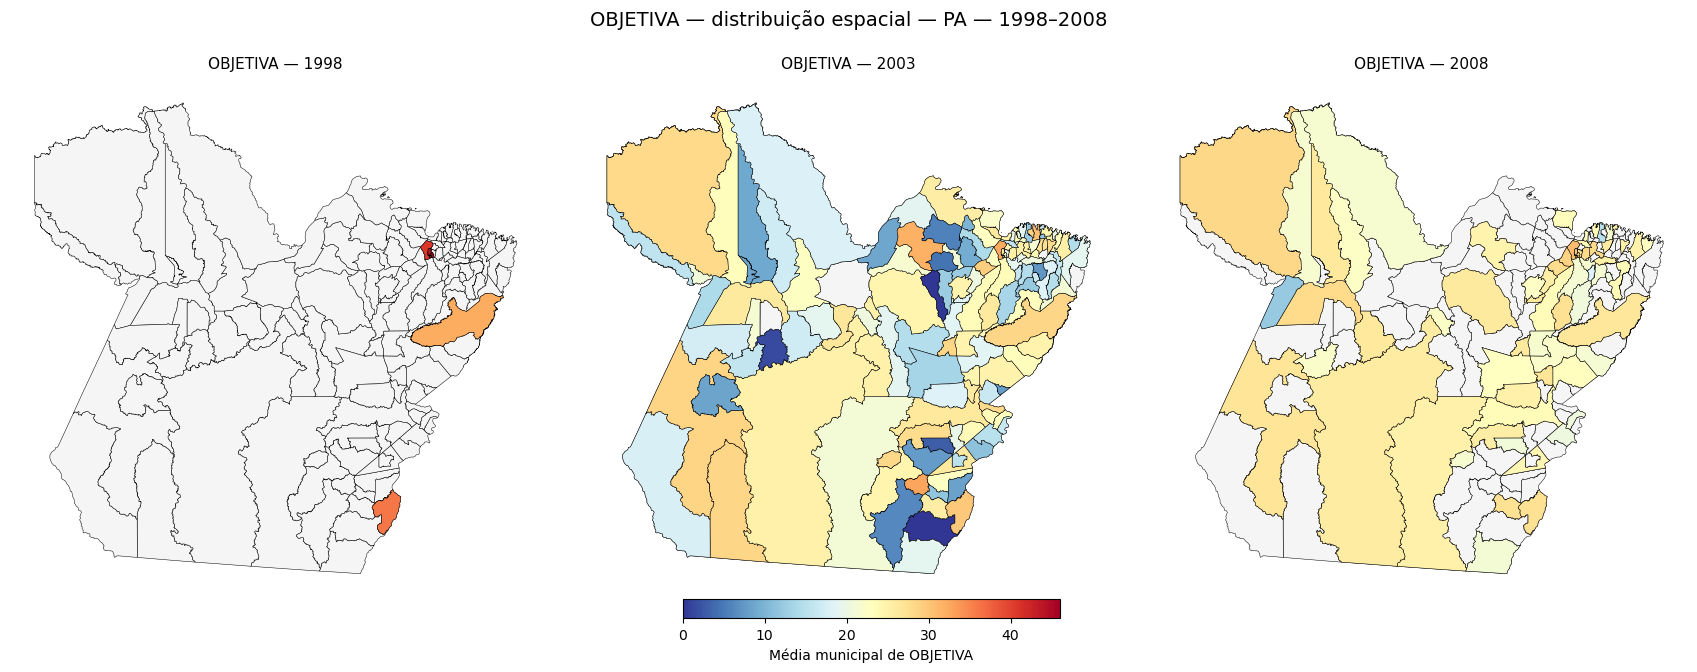

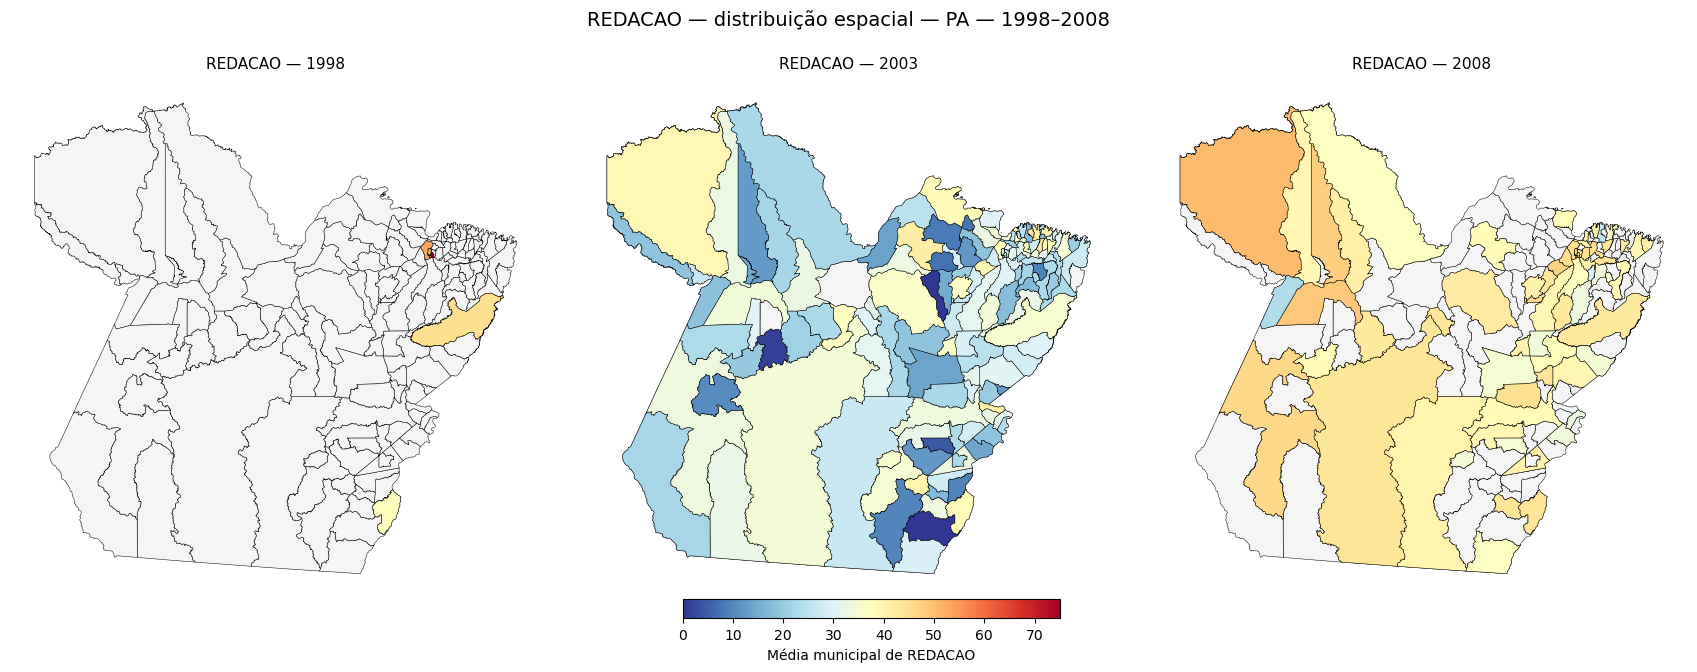


MAPAS DE REFERÊNCIA — 2009–2025


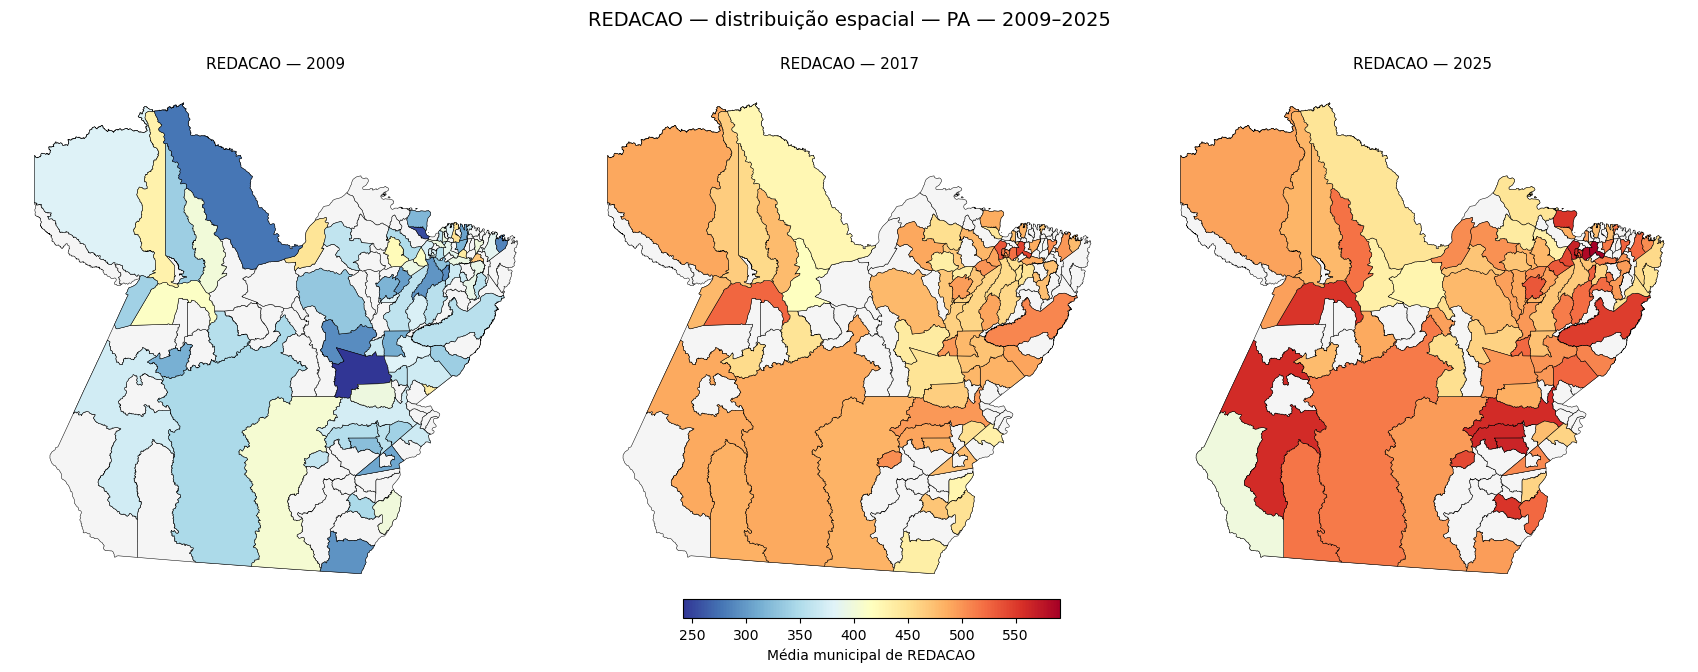

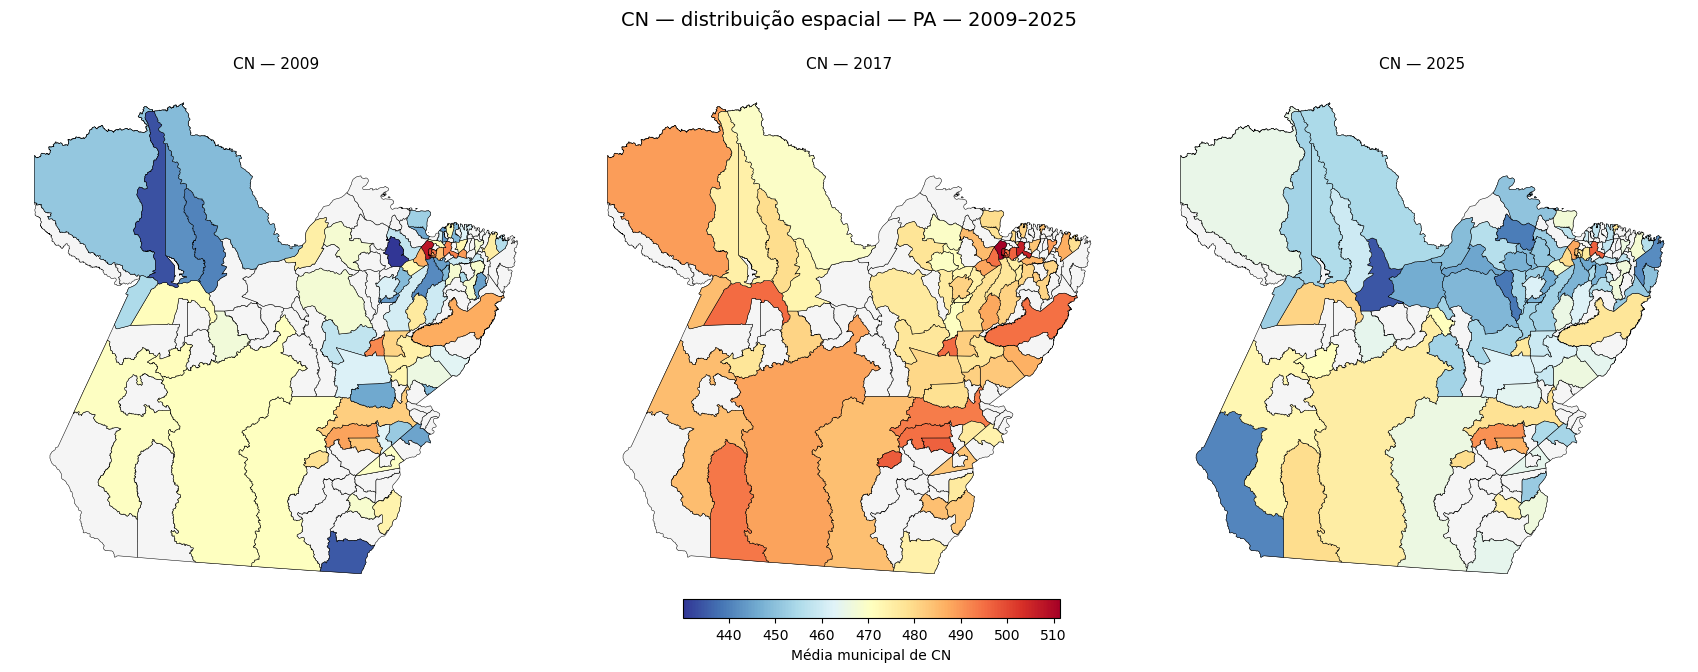

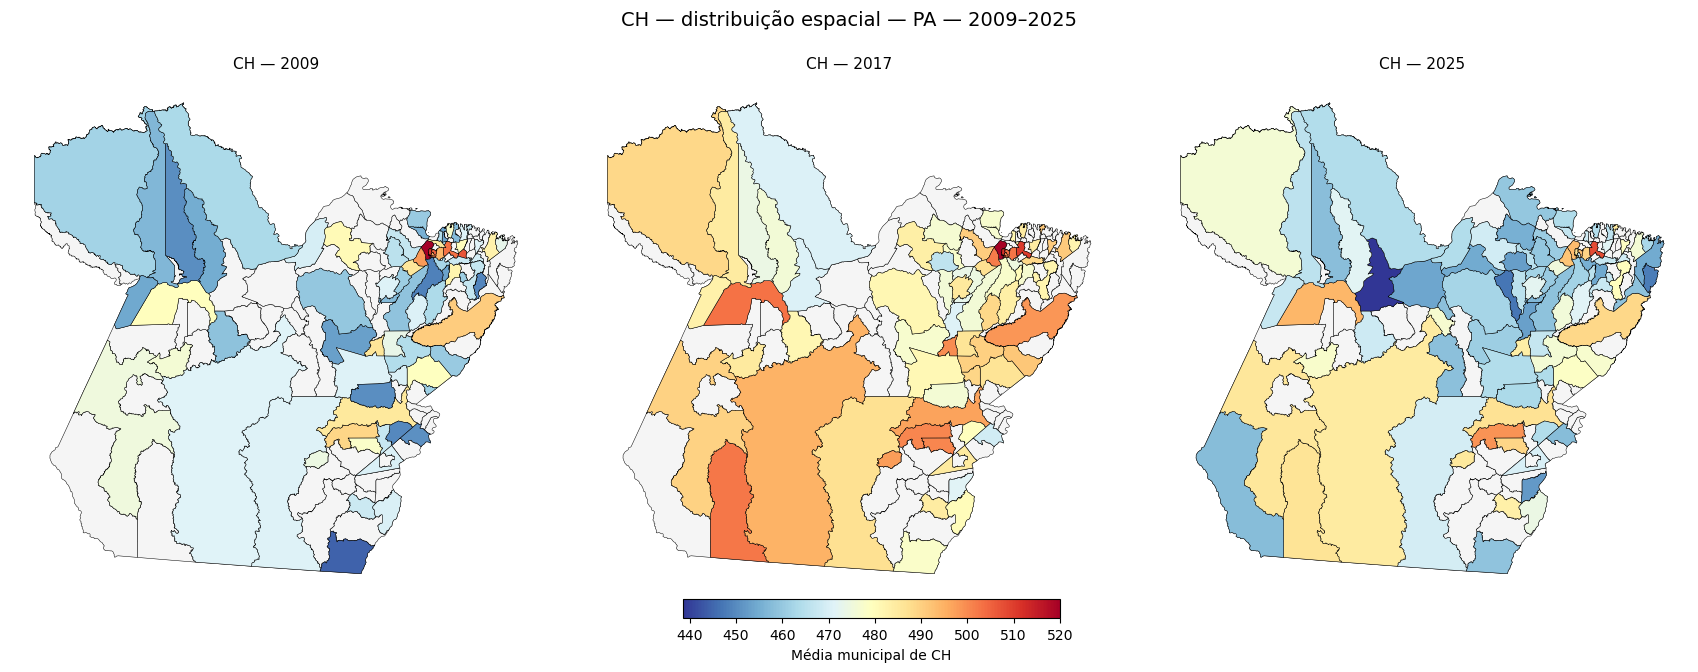

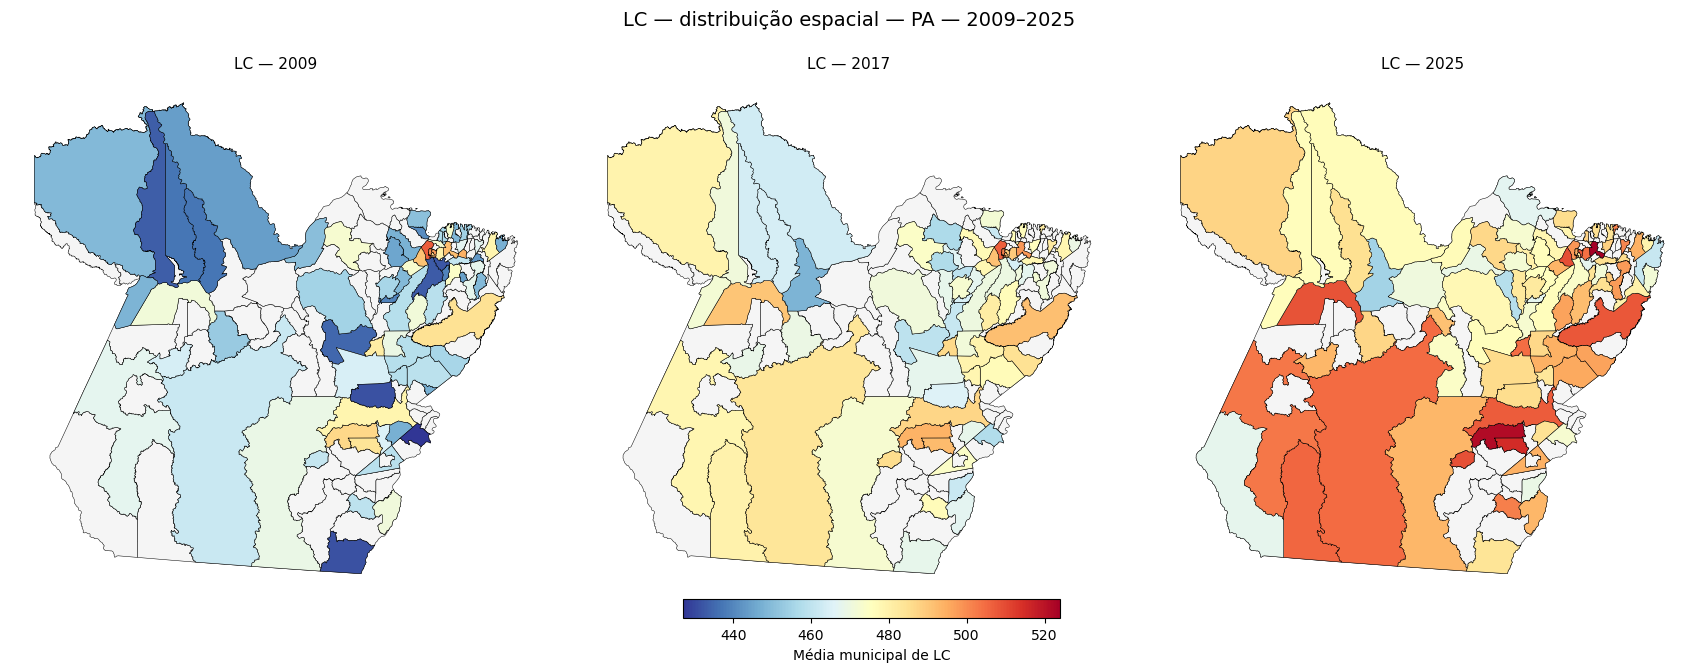

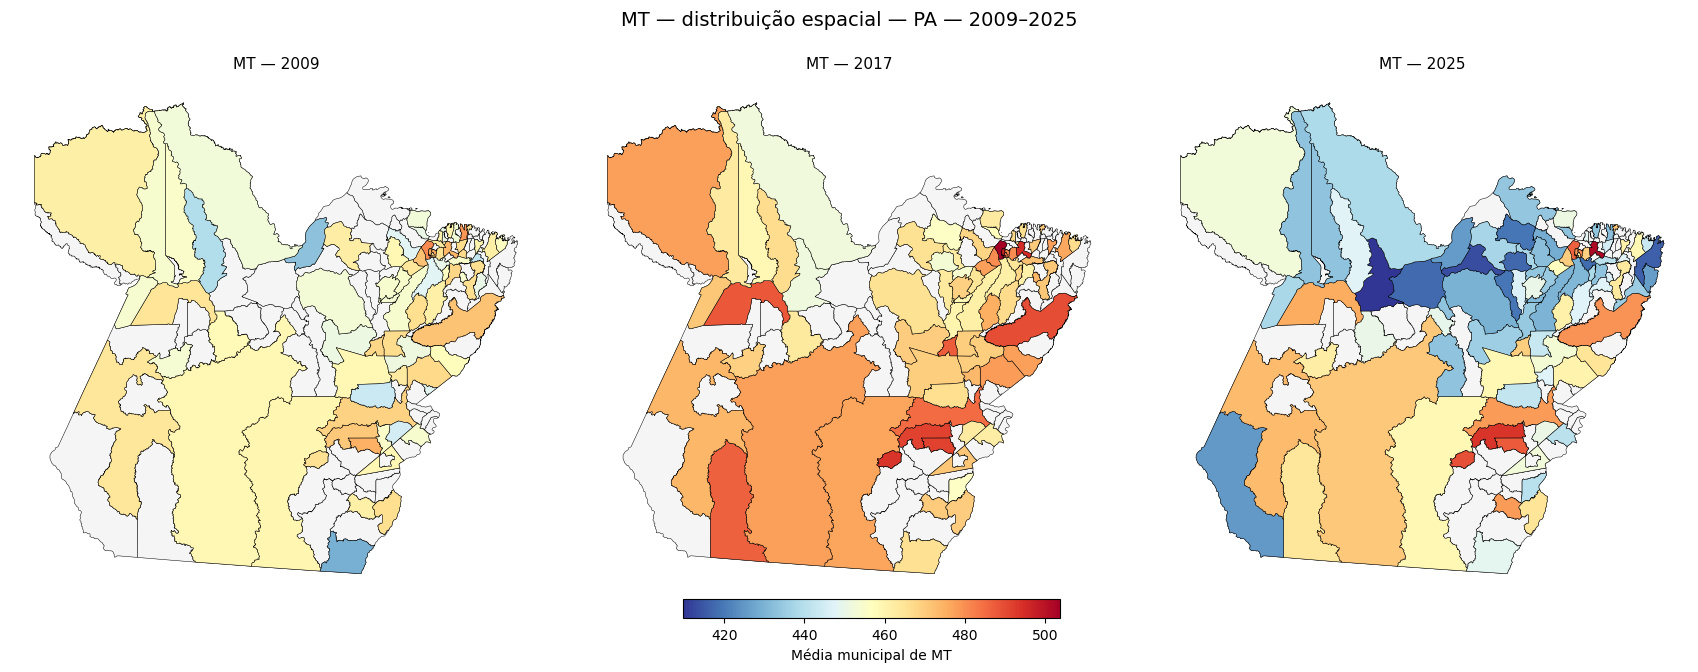

In [5]:
# ============================================================
# 4. MAPAS DOS ANOS DE REFERÊNCIA
# ============================================================

for periodo_id, disciplinas in DISCIPLINAS_PERIODOS.items():

    periodo = PERIODOS[periodo_id]
    anos_mapa = ANOS_REFERENCIA_DISPONIVEIS[periodo_id]

    if not anos_mapa:
        print(
            f"Sem anos de referência disponíveis para {periodo['rotulo']}."
        )
        continue

    print("\n" + "=" * 80)
    print(f"MAPAS DE REFERÊNCIA — {periodo['rotulo']}")
    print("=" * 80)

    for coluna, info in disciplinas.items():

        if coluna not in painel.columns:
            print(f"{info['nome']}: coluna {coluna} ausente. Mapa ignorado.")
            continue

        valores_periodo = pd.to_numeric(
            painel.loc[
                painel["ano"].isin(anos_mapa), coluna
            ],
            errors="coerce",
        ).dropna()

        if valores_periodo.empty:
            print(f"{info['nome']}: sem valores nos anos de referência.")
            continue

        vmin = float(valores_periodo.min())
        vmax = float(valores_periodo.max())

        if vmax == vmin:
            norm = Normalize(vmin=vmin - 0.5, vmax=vmax + 0.5)
        else:
            norm = Normalize(vmin=vmin, vmax=vmax)

        cmap = "RdYlBu_r"

        fig, axes = plt.subplots(
            1,
            len(anos_mapa),
            figsize=(6 * len(anos_mapa), 7),
            squeeze=False,
        )
        axes = axes.flatten()

        for ax, ano in zip(axes, anos_mapa):
            dados_ano = painel[painel["ano"] == ano].copy()
            dados_ano[coluna] = pd.to_numeric(
                dados_ano[coluna], errors="coerce"
            )

            mapa = preparar_mapa_municipal(
                dados_ano,
                coluna,
                nome_coluna_saida="valor_mapa",
            )

            desenhar_mapa_continuo(
                mapa,
                "valor_mapa",
                ax,
                f"{info['nome']} — {ano}",
                cmap=cmap,
                norm=norm,
            )

        fig.suptitle(
            f"{info['nome']} — distribuição espacial — "
            f"{UF_PROCESSAMENTO} — {periodo['rotulo']}",
            fontsize=14,
            y=0.98,
        )

        adicionar_colorbar(
            fig,
            axes,
            cmap,
            norm,
            f"Média municipal de {info['nome']}",
        )

        fig.subplots_adjust(left=0.03,right=0.97,
                            bottom=0.14,top=0.88,wspace=0.05)
        plt.show()



## 5. Mapas de variação entre os extremos de cada período

A variação é calculada como:

\[
\Delta = \text{média do ano final} - \text{média do ano inicial}
\]

São considerados apenas municípios com valores disponíveis nos dois anos. O mapa mantém os demais municípios em cinza, distinguindo ausência de pares válidos de uma variação próxima de zero.

Não calculamos variação percentual: a diferença absoluta em pontos é mais direta para os indicadores de desempenho e evita instabilidade quando a média inicial é zero ou muito baixa.


In [1]:
# ============================================================
# 5. MAPAS DE VARIAÇÃO ENTRE OS EXTREMOS DOS PERÍODOS
# ============================================================

for periodo_id, disciplinas in DISCIPLINAS_PERIODOS.items():

    periodo = PERIODOS[periodo_id]
    ano_inicial = periodo["inicio"]
    ano_final = periodo["fim"]

    anos_existentes = set(painel["ano"].unique())

    if ano_inicial not in anos_existentes or ano_final not in anos_existentes:
        print(
            f"Variação {periodo['rotulo']} ignorada: "
            f"não há registros em {ano_inicial} e/ou {ano_final}."
        )
        continue

    print("\n" + "=" * 80)
    print(
        f"MAPAS DE VARIAÇÃO — {ano_inicial} → {ano_final}"
    )
    print("=" * 80)

    for coluna, info in disciplinas.items():

        base_inicial = painel.loc[
            painel["ano"] == ano_inicial,
            [COLUNA_CODIGO_PAINEL, coluna],
        ].copy()

        base_final = painel.loc[
            painel["ano"] == ano_final,
            [COLUNA_CODIGO_PAINEL, coluna],
        ].copy()

        base_inicial[coluna] = pd.to_numeric(
            base_inicial[coluna], errors="coerce"
        )
        base_final[coluna] = pd.to_numeric(
            base_final[coluna], errors="coerce"
        )

        base_inicial = base_inicial.rename(
            columns={coluna: "media_inicial"}
        )
        base_final = base_final.rename(
            columns={coluna: "media_final"}
        )

        variacao = base_inicial.merge(
            base_final,
            on=COLUNA_CODIGO_PAINEL,
            how="inner",
            validate="one_to_one",
        )

        variacao["delta"] = (
            variacao["media_final"] - variacao["media_inicial"]
        )

        variacao = variacao.dropna(subset=["media_inicial", "media_final"])

        if variacao.empty:
            print(
                f"{info['nome']}: nenhum município com dados nos dois extremos."
            )
            continue

        mapa = preparar_mapa_municipal(
            variacao.assign(
                delta=variacao["delta"]
            ),
            "delta",
            nome_coluna_saida="delta",
        )

        norm = escala_divergente(mapa["delta"])
        fig, ax = plt.subplots(figsize=(10, 10))

        desenhar_mapa_continuo(
            mapa,
            "delta",
            ax,
            (
                f"Variação de {info['nome']} — "
                f"{ano_final} − {ano_inicial}"
            ),
            cmap="RdBu_r",
            norm=norm,
        )

        sm = ScalarMappable(norm=norm, cmap="RdBu_r")
        sm.set_array([])
        fig.colorbar(
            sm,
            ax=ax,
            shrink=0.65,
            label="Variação em pontos",
        )

        ax.set_title(
            f"{info['nome']} — {ano_final} − {ano_inicial} — "
            f"{UF_PROCESSAMENTO}\n"
            f"Municípios com pares válidos: {len(variacao)}",
            fontsize=13,
            pad=15,
        )

        plt.tight_layout()
        plt.show()

        print(
            f"{info['nome']}: {len(variacao)} municípios com dados "
            f"nos dois extremos."
        )



## 6. Mapas de tendência municipal

Para aproveitar todos os anos disponíveis, estimamos uma regressão linear por município e indicador, separadamente em cada período.

O mapa representa a inclinação da regressão em pontos por ano. Para reduzir a apresentação de tendências baseadas em poucas observações, exigimos pelo menos `MIN_ANOS_TENDENCIA` anos válidos por município.

**Importante:** os mapas destacam apenas inclinações com `p < ALPHA_TENDENCIA`. Municípios sem destaque podem não apresentar evidência estatística de tendência ou não ter observações suficientes. Os testes são exploratórios e não incluem correção para múltiplas comparações entre municípios.


In [2]:
# ============================================================
# 6. MAPAS DE TENDÊNCIA LINEAR MUNICIPAL
# ============================================================

for periodo_id, disciplinas in DISCIPLINAS_PERIODOS.items():

    periodo = PERIODOS[periodo_id]

    dados_periodo = painel[
        painel["ano"].between(periodo["inicio"], periodo["fim"])
    ].copy()

    if dados_periodo["ano"].nunique() < MIN_ANOS_TENDENCIA:
        print(
            f"Tendência {periodo['rotulo']} ignorada: "
            f"menos de {MIN_ANOS_TENDENCIA} anos disponíveis."
        )
        continue

    print("\n" + "=" * 80)
    print(f"MAPAS DE TENDÊNCIA — {periodo['rotulo']}")
    print("=" * 80)

    tendencias_periodo = calcular_tendencias_municipais(
        painel,
        periodo,
        disciplinas,
        min_anos=MIN_ANOS_TENDENCIA,
    )

    if tendencias_periodo.empty:
        print(f"Sem tendências municipais calculáveis em {periodo['rotulo']}.")
        continue

    for disciplina, info in disciplinas.items():

        dados_tendencia = tendencias_periodo[
            tendencias_periodo["disciplina"] == info["nome"]
        ].copy()

        if dados_tendencia.empty:
            print(f"{info['nome']}: sem tendências municipais calculáveis.")
            continue

        dados_tendencia["slope_pontos_ano"] = pd.to_numeric(
            dados_tendencia["slope_pontos_ano"], errors="coerce"
        )
        dados_tendencia["p_valor"] = pd.to_numeric(
            dados_tendencia["p_valor"], errors="coerce"
        )

        # Somente tendências com evidência estatística são coloridas.
        dados_tendencia["slope_significativo"] = dados_tendencia[
            "slope_pontos_ano"
        ].where(
            dados_tendencia["p_valor"] < ALPHA_TENDENCIA
        )

        mapa = preparar_mapa_municipal(
            dados_tendencia.rename(
                columns={
                    "slope_significativo": "slope_mapa"
                }
            ),
            "slope_mapa",
            nome_coluna_saida="slope_mapa")

        # ------------------------------------------------------------
      # Identificação dos municípios no mapa
      # ------------------------------------------------------------
        dados_tendencia["_codigo_municipio_join"] = codigo_como_texto(dados_tendencia["CO_MUNICIPIO_TERRITORIO"])
        
        nomes_municipios = dados_tendencia.set_index("_codigo_municipio_join")["NO_MUNICIPIO_TERRITORIO"]
        
        mapa["_nome_municipio"] = mapa["_codigo_municipio_join"].map(nomes_municipios)

        
        norm = escala_divergente(mapa["slope_mapa"])
        fig, ax = plt.subplots(figsize=(16, 10))

        desenhar_mapa_continuo(
            mapa,
            "slope_mapa",
            ax,
            f"Tendência municipal — {info['nome']}",
            cmap="RdBu",
            norm=norm)
        
        municipios_rotular = mapa[mapa["slope_mapa"].notna()].copy()

        for _, municipio in municipios_rotular.iterrows():
            ponto = municipio.geometry.representative_point()
            
            ax.annotate(text=municipio["_nome_municipio"],xy=(ponto.x, ponto.y),
                        ha="center",va="center",fontsize=4,color="black",fontweight="bold")

        sm = ScalarMappable(norm=norm, cmap="RdBu")
        sm.set_array([])
        fig.colorbar(
            sm,
            ax=ax,
            shrink=0.65,
            label="Inclinação (pontos por ano)",
        )

        n_municipios = dados_tendencia[
            "CO_MUNICIPIO_TERRITORIO"
        ].nunique()

        n_significativos = int(
            (
                dados_tendencia["p_valor"] < ALPHA_TENDENCIA
            ).sum()
        )

        ax.set_title(
            f"Tendência de {info['nome']} — {UF_PROCESSAMENTO} — "
            f"{periodo['rotulo']}\n"
            f"Municípios com tendência estimada: {n_municipios}; "
            f"com p < {ALPHA_TENDENCIA}: {n_significativos}",
            fontsize=12,
            pad=15,
        )

        plt.tight_layout()
        plt.show()



## 7. Síntese metodológica e limitações

1. **Períodos independentes:** 1998–2008 e 2009–2025 não são conectados em uma única série de desempenho.
2. **Redação:** os critérios antigo e novo são tratados separadamente.
3. **Anos de referência:** são marcos de visualização, não uma amostragem estatística de todos os anos.
4. **Variação:** mapas de diferença usam apenas municípios com valores válidos nos dois extremos.
5. **Tendência:** a inclinação linear resume a evolução observada, mas não demonstra causalidade.
6. **Significância:** os mapas de tendência destacam `p < 0,05`, sem correção para múltiplos testes. Devem ser interpretados como exploração espacial.
7. **Cobertura:** municípios sem cor podem representar ausência de dados, cobertura insuficiente ou tendência não significativa, conforme a seção.
8. **Referência territorial:** a malha municipal é a carregada por `read_allfiles()`. A compatibilidade histórica dos códigos territoriais deve ser considerada na interpretação.

Este notebook é exclusivamente cartográfico. As tabelas analíticas, estatísticas descritivas, rankings e interpretações longitudinais permanecem no notebook de análise longitudinal periodizada.


In [8]:
# ============================================================
# AUDITORIA DOS RESULTADOS DE TENDÊNCIA
# ============================================================

for periodo_id, disciplinas in DISCIPLINAS_PERIODOS.items():

    periodo = PERIODOS[periodo_id]

    tendencias = calcular_tendencias_municipais(
        painel,
        periodo,
        disciplinas,
        min_anos=MIN_ANOS_TENDENCIA,
    )

    print("\n" + "=" * 90)
    print(f"AUDITORIA DE TENDÊNCIAS — {periodo['rotulo']}")
    print("=" * 90)

    for disciplina in tendencias["disciplina"].unique():

        dados = tendencias[
            tendencias["disciplina"] == disciplina
        ].copy()

        significativos = dados[
            dados["p_valor"] < ALPHA_TENDENCIA
        ]

        print(f"\nIndicador: {disciplina}")
        print(f"Municípios estimados: {len(dados)}")
        print(f"Tendências significativas: {len(significativos)}")

        print(
            f"Tendências positivas: "
            f"{(dados['slope_pontos_ano'] > 0).sum()}"
        )

        print(
            f"Tendências negativas: "
            f"{(dados['slope_pontos_ano'] < 0).sum()}"
        )

        print(
            f"Quantidade de anos utilizados — mínimo: "
            f"{dados['n_anos'].min()}, "
            f"mediana: {dados['n_anos'].median()}, "
            f"máximo: {dados['n_anos'].max()}"
        )

        print(
            f"Ano inicial utilizado — mínimo: "
            f"{dados['ano_inicial'].min()}, "
            f"máximo: {dados['ano_inicial'].max()}"
        )

        print(
            f"Ano final utilizado — mínimo: "
            f"{dados['ano_final'].min()}, "
            f"máximo: {dados['ano_final'].max()}"
        )

        display(
            dados[
                [
                    "NO_MUNICIPIO_TERRITORIO",
                    "n_anos",
                    "ano_inicial",
                    "ano_final",
                    "slope_pontos_ano",
                    "r2",
                    "p_valor",
                ]
            ].sort_values("p_valor").head(10)
        )


AUDITORIA DE TENDÊNCIAS — 1998–2008

Indicador: OBJETIVA
Municípios estimados: 135
Tendências significativas: 14
Tendências positivas: 89
Tendências negativas: 46
Quantidade de anos utilizados — mínimo: 5, mediana: 8.0, máximo: 11
Ano inicial utilizado — mínimo: 1998, máximo: 2003
Ano final utilizado — mínimo: 2007, máximo: 2008


,NO_MUNICIPIO_TERRITORIO,n_anos,ano_inicial,ano_final,slope_pontos_ano,r2,p_valor
170,PLACAS,7,2001,2007,3.722632,0.839840,0.003706
128,MELGACO,8,2000,2007,4.269560,0.699123,0.009692
174,PORTEL,9,1999,2008,2.207242,0.595887,0.014801
116,MAE DO RIO,10,1999,2008,2.412587,0.539917,0.015488
218,SAO DOMINGOS DO CAPIM,8,2001,2008,2.411772,0.636751,0.017619
252,TRAIRAO,7,2001,2007,1.702485,0.698859,0.019118
248,TOME-ACU,9,2000,2008,1.697400,0.544534,0.023220
72,CONCORDIA DO PARA,9,2000,2008,1.878825,0.529622,0.026243
46,BRASIL NOVO,8,1999,2007,2.762323,0.576300,0.028925
92,GOIANESIA DO PARA,9,2000,2008,2.178146,0.501795,0.032691



Indicador: REDACAO
Municípios estimados: 135
Tendências significativas: 14
Tendências positivas: 81
Tendências negativas: 54
Quantidade de anos utilizados — mínimo: 5, mediana: 8.0, máximo: 11
Ano inicial utilizado — mínimo: 1998, máximo: 2003
Ano final utilizado — mínimo: 2007, máximo: 2008


,NO_MUNICIPIO_TERRITORIO,n_anos,ano_inicial,ano_final,slope_pontos_ano,r2,p_valor
171,PLACAS,7,2001,2007,5.111087,0.885726,0.001564
107,ITAITUBA,10,1999,2008,2.412592,0.588493,0.009607
129,MELGACO,8,2000,2007,6.400649,0.664503,0.013678
73,CONCORDIA DO PARA,9,2000,2008,2.678903,0.592222,0.015310
175,PORTEL,9,1999,2008,3.152607,0.572208,0.018326
117,MAE DO RIO,10,1999,2008,4.019898,0.512188,0.019946
239,SENADOR JOSE PORFIRIO,6,2001,2007,-3.928656,0.774099,0.020794
55,BUJARU,7,2002,2008,3.430514,0.670861,0.024201
167,PAU D'ARCO,5,2003,2007,5.688089,0.841667,0.028129
111,JACUNDA,10,1999,2008,2.608130,0.453062,0.032908



AUDITORIA DE TENDÊNCIAS — 2009–2025

Indicador: REDACAO
Municípios estimados: 77
Tendências significativas: 75
Tendências positivas: 77
Tendências negativas: 0
Quantidade de anos utilizados — mínimo: 6, mediana: 17.0, máximo: 17
Ano inicial utilizado — mínimo: 2009, máximo: 2020
Ano final utilizado — mínimo: 2025, máximo: 2025


,NO_MUNICIPIO_TERRITORIO,n_anos,ano_inicial,ano_final,slope_pontos_ano,r2,p_valor
280,REDENCAO,17,2009,2025,17.878341,0.746403,0.000008
90,CANAA DOS CARAJAS,17,2009,2025,20.308816,0.743825,0.000008
115,CONCORDIA DO PARA,17,2009,2025,17.182852,0.739347,0.000010
130,DOM ELISEU,17,2009,2025,16.132769,0.736375,0.000011
360,TUCUMA,17,2009,2025,16.169176,0.730985,0.000012
250,PARAGOMINAS,17,2009,2025,17.699730,0.726929,0.000014
190,MARABA,17,2009,2025,17.571261,0.722314,0.000016
255,PARAUAPEBAS,17,2009,2025,17.940669,0.710321,0.000022
220,NOVO REPARTIMENTO,17,2009,2025,19.610200,0.709982,0.000022
355,TOME-ACU,17,2009,2025,15.777868,0.705986,0.000024


... (4 outputs left out)


Indicador: LC
Municípios estimados: 77
Tendências significativas: 21
Tendências positivas: 73
Tendências negativas: 4
Quantidade de anos utilizados — mínimo: 6, mediana: 17.0, máximo: 17
Ano inicial utilizado — mínimo: 2009, máximo: 2020
Ano final utilizado — mínimo: 2025, máximo: 2025


,NO_MUNICIPIO_TERRITORIO,n_anos,ano_inicial,ano_final,slope_pontos_ano,r2,p_valor
148,GOIANESIA DO PARA,17,2009,2025,1.750384,0.563719,0.000514
163,ITAITUBA,17,2009,2025,2.199627,0.547970,0.000679
213,MONTE ALEGRE,17,2009,2025,2.195654,0.457414,0.002873
363,TUCUMA,17,2009,2025,1.968802,0.445932,0.003396
283,REDENCAO,17,2009,2025,1.750587,0.442178,0.003585
318,SANTAREM,17,2009,2025,1.769123,0.428157,0.004374
218,NOVO PROGRESSO,14,2012,2025,2.612224,0.467291,0.007029
23,ALTAMIRA,17,2009,2025,1.715260,0.376928,0.008750
258,PARAUAPEBAS,17,2009,2025,1.438739,0.366898,0.009966
133,DOM ELISEU,17,2009,2025,1.685927,0.356622,0.011369



Indicador: MT
Municípios estimados: 77
Tendências significativas: 23
Tendências positivas: 74
Tendências negativas: 3
Quantidade de anos utilizados — mínimo: 6, mediana: 17.0, máximo: 17
Ano inicial utilizado — mínimo: 2009, máximo: 2020
Ano final utilizado — mínimo: 2025, máximo: 2025


,NO_MUNICIPIO_TERRITORIO,n_anos,ano_inicial,ano_final,slope_pontos_ano,r2,p_valor
284,REDENCAO,17,2009,2025,2.990617,0.440512,0.003671
164,ITAITUBA,17,2009,2025,3.026789,0.426672,0.004466
109,CASTANHAL,17,2009,2025,2.709636,0.419076,0.004964
24,ALTAMIRA,17,2009,2025,2.583026,0.417280,0.005089
319,SANTAREM,17,2009,2025,2.736387,0.407000,0.005860
364,TUCUMA,17,2009,2025,2.276999,0.406288,0.005917
259,PARAUAPEBAS,17,2009,2025,2.459751,0.397733,0.006642
214,MONTE ALEGRE,17,2009,2025,2.349239,0.382275,0.008157
194,MARABA,17,2009,2025,2.503284,0.381212,0.008272
94,CANAA DOS CARAJAS,17,2009,2025,2.373054,0.355238,0.011571
